# Box following demo

In [1]:
import torch
from utils import run_case, show

print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 2070


/usr/local/lib/python3.12/dist-packages/torch/cuda/__init__.py:435: UserWarning: 
    Found GPU0 NVIDIA GeForce RTX 2070 which is of cuda capability 7.5.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (7.5) - (12.0)
    
  queued_call()
/usr/local/lib/python3.12/dist-packages/torch/cuda/__init__.py:435: UserWarning: 
    Please install PyTorch with a following CUDA
    configurations:  12.6 12.8 following instructions at
    https://pytorch.org/get-started/locally/
    
  queued_call()


Two 2 x 2 swaps.

In [2]:
SHAPE, PERM = (2, 2, 2, 2, 16777216), (1, 0, 3, 2, 4)
results = run_case(SHAPE, PERM)

shape (2, 2, 2, 2, 16777216), permutation (1, 0, 3, 2, 4): 268,435,456 elements, 1.00 GB

BOX FOLLOWING
  swap 1: d_pre=4  rows=2  cols=2  d_post=16,777,216
  swap 2: d_pre=1  rows=2  cols=2  d_post=67,108,864
  planning time   15.40 ms
  upload to GPU   1.99 ms
  plan memory     16 bytes
  address         0x72fef4000000 -> 0x72fef4000000   same: True
  buffer size     1,073,741,824 -> 1,073,741,824 bytes   same: True
  correct         True

.contiguous()
  address         0x72fef4000000 -> 0x72fe5c000000   same: False
  correct         True

ITTPD
  address         0x72fe5c000000 -> 0x72fe5c000000   same: True
  buffer size     1,073,741,824 -> 1,073,741,824 bytes   same: True
  correct         True

Gustavson
  address         0x72c380000000 -> 0x72c380000000   same: True
  buffer size     1,073,741,824 -> 1,073,741,824 bytes   same: True
  correct         True

Gomez-Luna
  address         0x7a6e7a000000 -> 0x7a6e7a000000   same: True
  buffer size     1,073,741,824 -> 1,073,741,824

,Runtime (ms),Speedup vs baseline,Data movement Amplification,Extra memory,In place,Correct
Method,,,,,,
PyTorch .contiguous(),7.17,1.0x (baseline),1.0x,1.0 GB,no,yes
Box following (ours),7.00,1.02x,2.0x,16 bytes,yes,yes
ITTPD,14.88,0.48x,2.0x,0 bytes,yes,yes
Gustavson,111.61,0.06x,2.0x,0 bytes,yes,yes
Gomez-Luna,340.37,0.02x,2.0x,16 bytes,yes,yes


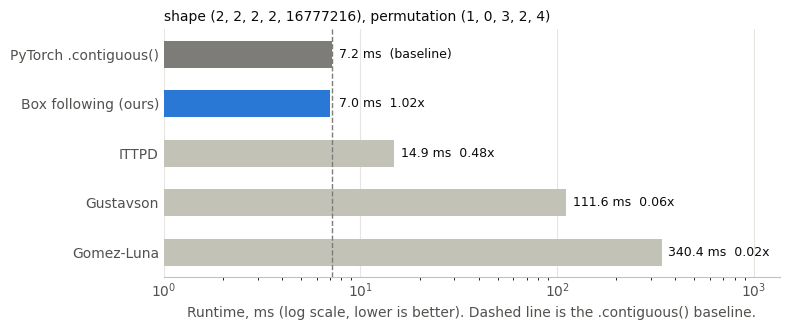

In [3]:
show(results, SHAPE, PERM)